In [1]:
from pathlib import Path

import harmonypy as hm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")
tcel = adata[adata.obs["tipo"] == "Linfocito T"].copy()
tcel.obs["muestra"] = tcel.obs["muestra"].cat.remove_unused_categories()

print(tcel)
print(tcel.obs["muestra"].value_counts().sort_values())

AnnData object with n_obs × n_vars = 1581 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'condicion_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'muestra_colors', 'neighbors', 'pca', 'rank_genes_groups', 'scrublet', 'tipo_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'


In [2]:
sc.pp.highly_variable_genes(tcel, n_top_genes=2000, batch_key="muestra")

excluir = tcel.var_names.str.match(r"^(TR[ABDG][VJ]|IG[HKL][VJ]|MT-|RP[SL])")
tcel.var.loc[excluir, "highly_variable"] = False
print("Genes excluidos:", excluir.sum(), "| Genes variables:", tcel.var["highly_variable"].sum())

Genes excluidos: 184 | Genes variables: 1922


In [3]:
sc.pp.pca(tcel, n_comps=30, mask_var="highly_variable")

ho = hm.run_harmony(tcel.obsm["X_pca"], tcel.obs, "muestra", random_state=0)
z = np.asarray(ho.Z_corr)
assert z.shape == tcel.obsm["X_pca"].shape, z.shape
tcel.obsm["X_pca_harmony"] = z

2026-10-30 22:38:29,074 - harmonypy - INFO - Running Harmony
2026-10-30 22:38:29,075 - harmonypy - INFO -   Parameters:
2026-10-30 22:38:29,075 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-30 22:38:29,075 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-30 22:38:29,076 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-30 22:38:29,076 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-30 22:38:29,077 - harmonypy - INFO -     nclust: 53
2026-10-30 22:38:29,077 - harmonypy - INFO -     block_size: 0.05
2026-10-30 22:38:29,077 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-30 22:38:29,078 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-30 22:38:29,078 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-30 22:38:29,079 - harmonypy - INFO -     verbose: True
2026-10-30 22:38:29,079 - harmonypy - INFO -     random_state: 0
2026-10-30 22:38:29,079 - harmonypy - INFO -   Data: 30 PCs × 1581 cells
2026-10-30

In [4]:
sc.pp.neighbors(tcel, use_rep="X_pca_harmony", n_pcs=20)
sc.tl.umap(tcel, random_state=0)
sc.tl.leiden(tcel, resolution=0.5, flavor="igraph", n_iterations=2,
             key_added="leiden_T", random_state=0)
tcel.obs["leiden_T"].value_counts().sort_index()

leiden_T
0     423
1      59
2     132
3     256
4     156
5      92
6      52
7      63
8     271
9      48
10     29
Name: count, dtype: int64

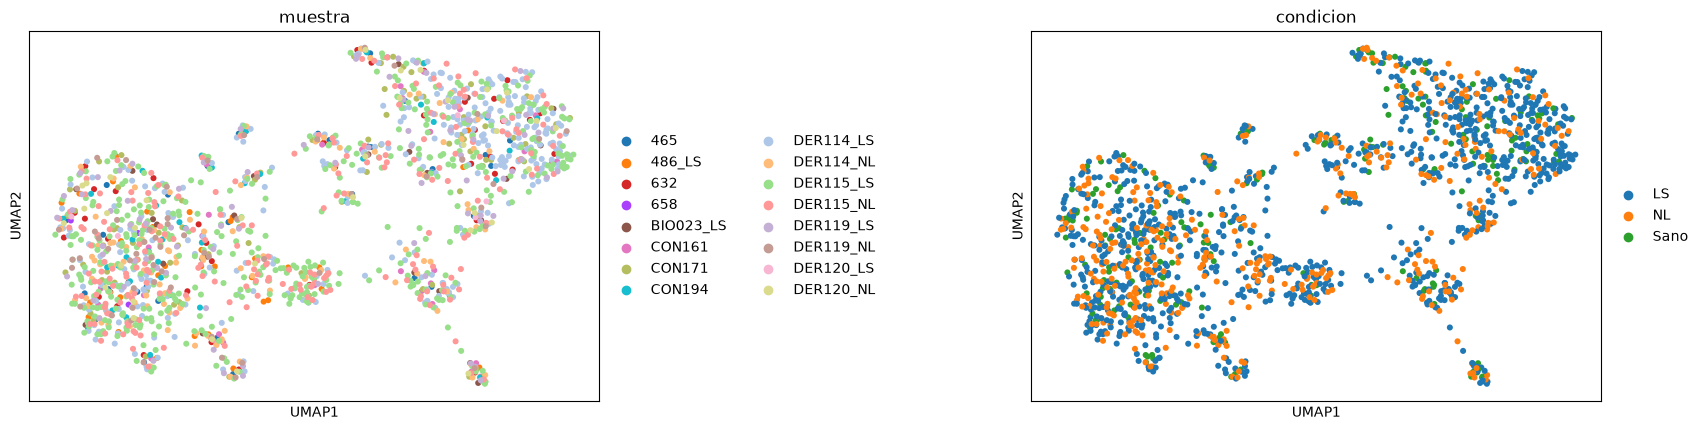

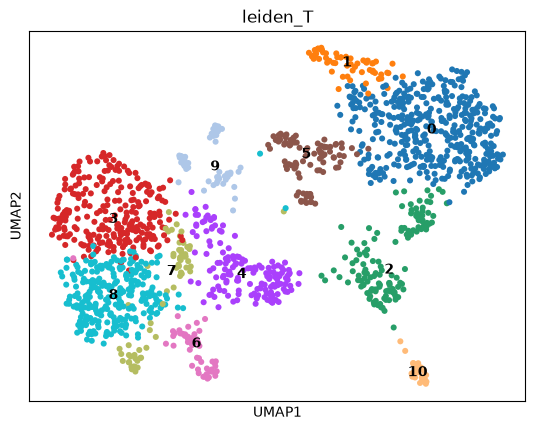

In [5]:
sc.pl.umap(tcel, color=["muestra", "condicion"], ncols=2, wspace=0.6, show=False)
plt.savefig(DIR_FIGURAS / "umap_T_muestra_condicion.png", dpi=150, bbox_inches="tight")

sc.pl.umap(tcel, color="leiden_T", legend_loc="on data", show=False)
plt.savefig(DIR_FIGURAS / "umap_T_subclusters.png", dpi=150, bbox_inches="tight")

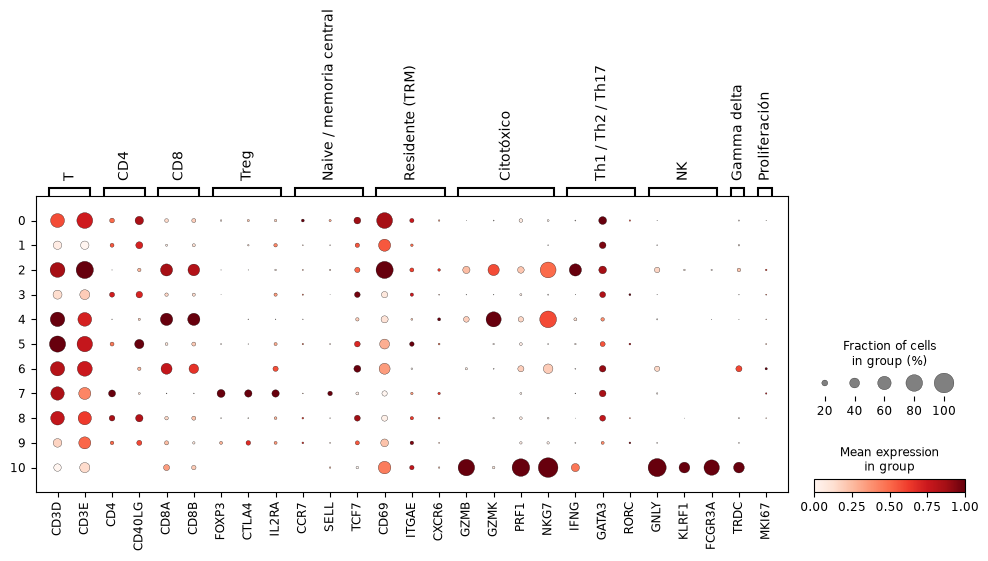

In [6]:
marcadores_T = {
    "T": ["CD3D", "CD3E"],
    "CD4": ["CD4", "CD40LG"],
    "CD8": ["CD8A", "CD8B"],
    "Treg": ["FOXP3", "CTLA4", "IL2RA"],
    "Naive / memoria central": ["CCR7", "SELL", "TCF7"],
    "Residente (TRM)": ["CD69", "ITGAE", "CXCR6"],
    "Citotóxico": ["GZMB", "GZMK", "PRF1", "NKG7"],
    "Th1 / Th2 / Th17": ["IFNG", "GATA3", "RORC"],
    "NK": ["GNLY", "KLRF1", "FCGR3A"],
    "Gamma delta": ["TRDC"],
    "Proliferación": ["MKI67"],
}
marcadores_T = {k: [g for g in v if g in tcel.var_names] for k, v in marcadores_T.items()}

sc.pl.dotplot(tcel, marcadores_T, groupby="leiden_T", standard_scale="var", show=False)
plt.savefig(DIR_FIGURAS / "dotplot_T_subclusters.png", dpi=150, bbox_inches="tight")


In [7]:
por_muestra = pd.crosstab(tcel.obs["leiden_T"], tcel.obs["muestra"])
por_muestra["total"] = por_muestra.sum(axis=1)
por_muestra["muestras_con_5_o_mas"] = (por_muestra.drop(columns="total") >= 5).sum(axis=1)
por_muestra

muestra,465,486_LS,632,658,BIO023_LS,CON161,CON171,CON194,DER114_LS,DER114_NL,DER115_LS,DER115_NL,DER119_LS,DER119_NL,DER120_LS,DER120_NL,total,muestras_con_5_o_mas
leiden_T,,,,,,,,,,,,,,,,,,
0,5,2,13,0,6,9,27,7,150,13,109,39,26,6,2,9,423,13
1,1,0,3,0,1,3,7,3,12,3,8,7,6,2,0,3,59,5
2,3,0,1,0,3,6,4,0,27,11,42,22,6,2,2,3,132,6
3,5,8,8,2,4,1,15,9,35,20,74,31,16,18,2,8,256,12
4,1,9,1,0,1,2,4,0,16,8,68,37,4,3,0,2,156,5
5,5,2,1,0,2,2,6,2,17,7,25,15,3,3,0,2,92,6
6,2,3,2,0,2,2,1,0,5,9,13,2,4,5,0,2,52,4
7,2,6,5,0,1,2,2,2,10,5,15,7,3,3,0,0,63,6
8,6,5,2,1,4,3,12,12,38,28,86,47,11,12,0,4,271,10


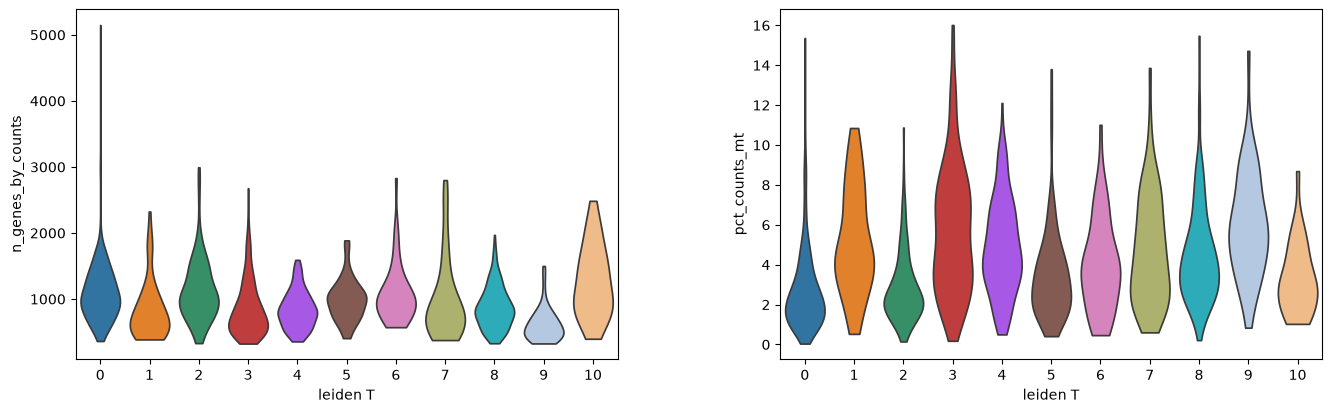

In [8]:
sc.pl.violin(tcel, ["n_genes_by_counts", "pct_counts_mt"], groupby="leiden_T",
             size=0, show=False)
plt.savefig(DIR_FIGURAS / "violin_T_calidad_subclusters.png", dpi=150, bbox_inches="tight")

In [8]:
anot_T = {
    "0": "CD4 residente",
    "1": "Baja calidad",
    "2": "CD8 IFNG+",
    "3": "CD4 memoria",
    "4": "CD8 GZMK+",
    "5": "CD4 residente",
    "6": "CD8 / gamma delta",
    "7": "Treg",
    "8": "CD4 memoria",
    "9": "Baja calidad",
    "10": "NK",
}
assert set(anot_T) == set(tcel.obs["leiden_T"].cat.categories)
tcel.obs["subtipo_T"] = tcel.obs["leiden_T"].map(anot_T).astype("category")

tcel_limpio = tcel[~tcel.obs["subtipo_T"].isin(["NK", "Baja calidad"])].copy()
tcel_limpio.obs["subtipo_T"] = tcel_limpio.obs["subtipo_T"].cat.remove_unused_categories()
tcel_limpio.obs["subtipo_T"].value_counts()

subtipo_T
CD4 memoria          527
CD4 residente        515
CD8 GZMK+            156
CD8 IFNG+            132
Treg                  63
CD8 / gamma delta     52
Name: count, dtype: int64

subtipo_T,CD4 memoria,CD4 residente,CD8 / gamma delta,CD8 GZMK+,CD8 IFNG+,Treg,condicion,n_T
muestra,,,,,,,,
465,37.9,34.5,6.9,3.4,10.3,6.9,Sano,29
486_LS,37.1,11.4,8.6,25.7,0.0,17.1,LS,35
632,30.3,42.4,6.1,3.0,3.0,15.2,Sano,33
BIO023_LS,34.8,34.8,8.7,4.3,13.0,4.3,LS,23
CON161,14.8,40.7,7.4,7.4,22.2,7.4,Sano,27
CON171,38.0,46.5,1.4,5.6,5.6,2.8,Sano,71
CON194,65.6,28.1,0.0,0.0,0.0,6.2,Sano,32
DER114_LS,24.5,56.0,1.7,5.4,9.1,3.4,LS,298
DER114_NL,47.5,19.8,8.9,7.9,10.9,5.0,NL,101


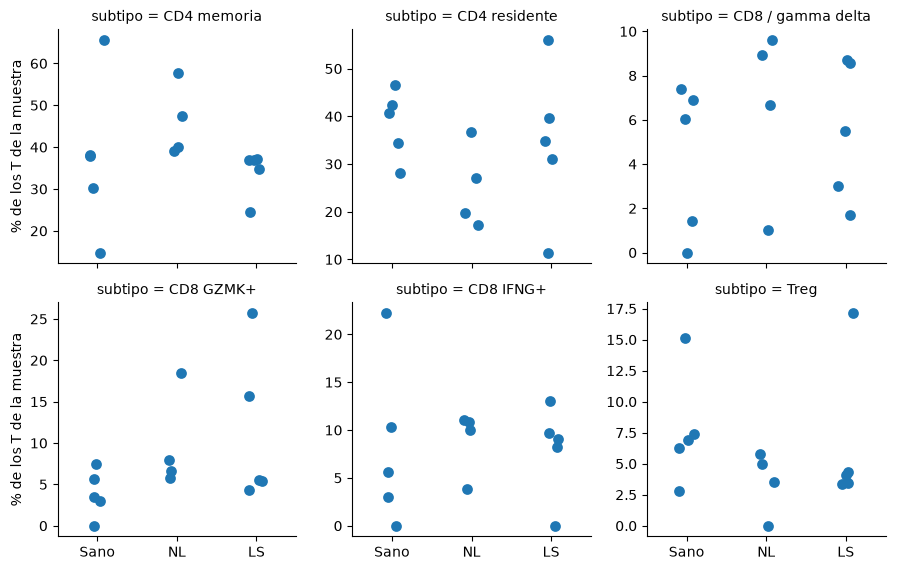

In [13]:
import seaborn as sns

prop = pd.crosstab(tcel_limpio.obs["muestra"], tcel_limpio.obs["subtipo_T"],
                   normalize="index").mul(100)
prop.columns = prop.columns.astype(str)
prop["condicion"] = tcel_limpio.obs.groupby("muestra", observed=True)["condicion"].first()
prop["n_T"] = tcel_limpio.obs["muestra"].value_counts()
prop = prop[prop["n_T"] >= 20]
prop.round(1).to_csv(DIR_TABLAS / "subtipos_T_por_muestra.csv")

largo = prop.reset_index().melt(id_vars=["muestra", "condicion", "n_T"],
                                var_name="subtipo", value_name="pct")
g = sns.catplot(data=largo, x="condicion", y="pct", col="subtipo", kind="strip",
                col_wrap=3, order=["Sano", "NL", "LS"], sharey=False, height=3, s=60)
g.set_axis_labels("", "% de los T de la muestra")
g.savefig(DIR_FIGURAS / "subtipos_T_por_condicion.png", dpi=150, bbox_inches="tight")
prop.round(1)

In [15]:
from scipy.stats import false_discovery_control, mannwhitneyu, spearmanr

subtipos = [c for c in prop.columns if c not in ("condicion", "n_T")]
orden = {"Sano": 0, "NL": 1, "LS": 2}

filas = []
for s in subtipos:
    g = {c: prop.loc[prop["condicion"] == c, s] for c in orden}
    rho = spearmanr(prop["condicion"].map(orden), prop[s])
    filas.append({"subtipo": s,
                  "mediana_Sano": g["Sano"].median(),
                  "mediana_NL": g["NL"].median(),
                  "mediana_LS": g["LS"].median(),
                  "p_NL_vs_Sano": mannwhitneyu(g["NL"], g["Sano"]).pvalue,
                  "p_LS_vs_Sano": mannwhitneyu(g["LS"], g["Sano"]).pvalue,
                  "rho_tendencia": rho.statistic,
                  "p_tendencia": rho.pvalue})

res = pd.DataFrame(filas).set_index("subtipo")
for col in ["p_NL_vs_Sano", "p_LS_vs_Sano", "p_tendencia"]:
    res[col.replace("p_", "q_")] = false_discovery_control(res[col])

res.round(3).to_csv(DIR_TABLAS / "subtipos_T_estadistica.csv")
res.round(3)

,mediana_Sano,mediana_NL,mediana_LS,p_NL_vs_Sano,p_LS_vs_Sano,rho_tendencia,p_tendencia,q_NL_vs_Sano,q_LS_vs_Sano,q_tendencia
subtipo,,,,,,,,,,
CD4 memoria,37.931,43.762,36.986,0.190,0.548,-0.231,0.428,0.286,0.821,0.680
CD4 residente,40.741,23.401,34.783,0.063,0.690,-0.189,0.518,0.190,0.829,0.680
CD8 / gamma delta,6.061,7.789,5.479,0.413,0.548,0.168,0.567,0.495,0.821,0.680
CD8 GZMK+,3.448,7.294,5.479,0.063,0.222,0.377,0.183,0.190,0.821,0.680
CD8 IFNG+,5.634,10.446,9.060,0.556,0.917,0.042,0.887,0.556,0.917,0.887
Treg,6.897,4.225,4.110,0.111,0.548,-0.294,0.308,0.222,0.821,0.680


In [16]:
tcel_limpio.write_h5ad(DIR_PROCESADOS / "04_linfocitos_T.h5ad")